# Лабораторная работа №3

ФИО: Григорьев Владислав Алексеевич  
Группа: БИВТ-24-СП-4

Отправлять можно следующими способами:
1. Запушить этот ноутбук в GitHub в репозиторий, где у вас лежат ноутбуки с лабами

Deadlines:
- Занятие №6 в семестре

Что необходимо сделать:  
- Обучить различного рода модели машинного обучения и сравнить их между собой  

---
## Читайте задание внимательно

Исходные данные:
1. В [табличке](https://docs.google.com/spreadsheets/d/1NOE0D4JQgD6LbvUqWboUI1TFj4P87ugbqUTDquxlGEI/edit?usp=sharing) необходимо узнать название своего датасета 
2. Скачать нужны вам данные можно в [Google Drive](https://drive.google.com/drive/folders/1sbsjBsJ_ln0XgXCI9R6s17pvyvApgcwF?usp=sharing)
  
---
Теперь по пунктам, что я от вас жду:  
1. Загрузить необходимые данные к себе и считать (read) их в переменную.
2. Понять, у вас задача классификации (бинарной или многоклассовой) или регрессии (**если у вас многоклассовая классификация, прочтите P.S.S. внизу**).
3. Сделать предобработку данных:  
     1. Разделить выборку на тренировочную (train) и тестовую (test). _Обратите внимание, что обучать скейлеры и определять, какими значениями вы будете заполнять пропуски, вы будете на train выборке, а применять и на train, и на test_.
     2. Проверить пропуски в данных. Если они есть, заполнить одной из стратегий, предложенных в ноутбуке для семинара №3. P.S. Для численных и категориальных переменных будут разные стратегии.
     3. Отнормировать численные переменные (`StandardScaler`, `MinMaxScaler`).
     4. Закодировать категориальные признаки по одной из стратегий.
4. Обучить на тренировочном множестве:
     1. Линейную модель (`LogisticRegression`, `LinearRegression`)
     2. Деревянную модель (`DecisionTreeClassifier`, `DecisionTreeRegressor`) (тут советую попробовать разные глубины деревьев)
     3. K-ближайших соседей (`KNeighborsClassifier`, `KNeighborsRegressor`) (тут тоже есть смысл попробовать разные `k`)
     4. Случайный лес (`RandomForestClassifier`, `RandomForestRegressor`) 
5. Посчитайте метрики на train и test множествах:
     1. Для задачи классификации -- Accuracy, ROC-AUC (график + значение), PR-кривую (график), F1-score
     2. Для задачи регрессии -- MAE, RMSE, MAPE
6. Сравните метрики относительно train/test, так и относительно разных моделей. Ответьте на следующие вопросы:
     1. Какая модель справилась лучше с поставленной задачей?
     2. Имеет ли место переобучение?
     3. Имеет ли место недообучение?
     4. Как можно улучшить метрики моделей?

---
P.S.  
Просьба -- делать каждое задание в отдельных ячейках и с отдельными заголовками (как пункт 1 и 2 в этом ноутбуке) типа  
- Заголовок
- Ячейки с кодом
- Другой заголовок
- Другие ячейки с кодом

P.S.S.  
Если вам повезло с многоклассовой классификацией, вам будет необходимо понять, умеет ли алгоритм работать с несколькими классами одновременно (обычно они не умеют). Поэтому вам может понадобиться такая штука, как OneVsRestClassifier ([ссылка](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html#sklearn.multiclass.OneVsRestClassifier)), но советую ознакомиться с этой [страницей](https://scikit-learn.org/stable/modules/multiclass.html), здесь представлена более полная информация.

## 1. Пример импорта данных. Грузим данные

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
RANDOM_STATE = 42

# Датасет лежит в AI-LABS/data/, ноутбук — в AI-LABS/notebooks/lr03/
path_to_dataset = '../../data/Sleep_health_and_lifestyle_dataset.csv'

# keep_default_na=False — чтобы pandas не превращал строку 'None'
# в столбце Sleep Disorder в NaN (это валидный класс «нет расстройства»)
data = pd.read_csv(path_to_dataset, keep_default_na=False)
print('Размер датасета:', data.shape)
data.head()

Размер датасета: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 2. Понимаем, какая перед нами задача

In [2]:
"""
Задача — многоклассовая классификация (multiclass classification).

Целевая переменная: Sleep Disorder
Классы: None (нет расстройства), Sleep Apnea (апноэ), Insomnia (бессонница) — 3 класса.

Значит, метрики:
- Accuracy, F1-score (macro-усреднение)
- ROC-AUC (multi_class='ovr', average='macro')
- ROC и PR-кривые — по одной на каждый класс (one-vs-rest)

Метрики регрессии (MAE/RMSE/MAPE) здесь НЕ нужны.

Про P.S.S.: все 4 базовых классификатора из sklearn (LogisticRegression,
DecisionTree, KNeighbors, RandomForest) нативно поддерживают multiclass.
Но по заданию покажу OneVsRestClassifier на примере LogisticRegression —
это универсальный способ «научить» многоклассовой задаче любой бинарный алгоритм.
"""

print('Распределение классов:')
print(data['Sleep Disorder'].value_counts())
print()
print('Уникальных значений целевой переменной:', data['Sleep Disorder'].nunique())

Распределение классов:
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

Уникальных значений целевой переменной: 3


## 3. Делаем предобработку данных

In [3]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

# ---------- 3.0. Лёгкая подготовка признаков ----------
df = data.copy()

# Person ID — служебный, в модель не идёт
df = df.drop(columns=['Person ID'])

# Унифицируем BMI Category: 'Normal Weight' и 'Normal' — это одно и то же
df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})

# Blood Pressure ('126/83') разбиваем на два числовых признака
df[['Systolic', 'Diastolic']] = df['Blood Pressure'].str.split('/', expand=True).astype(int)
df = df.drop(columns=['Blood Pressure'])

# ---------- 3.1. X и y, кодируем целевую ----------
X = df.drop(columns=['Sleep Disorder'])
y_raw = df['Sleep Disorder']

le = LabelEncoder()
y = le.fit_transform(y_raw)
CLASS_NAMES = le.classes_  # ['Insomnia', 'None', 'Sleep Apnea']
CLASS_IDS = list(range(len(CLASS_NAMES)))
print('Классы:', dict(zip(CLASS_NAMES, CLASS_IDS)))

# ---------- 3.2. Train/test split ----------
# stratify — чтобы доли классов сохранились в train и test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, '  Test:', X_test.shape)

# ---------- 3.3. Пропуски ----------
print('\nПропуски в train:')
print(X_train.isna().sum().sum(), 'всего')
print('Пропуски в test:')
print(X_test.isna().sum().sum(), 'всего')

# ---------- 3.4. Трансформеры ----------
# ВАЖНО: обучаются ТОЛЬКО на train внутри Pipeline, потому что
# ColumnTransformer/pipeline.fit(X_train) — а при .predict/test — применяет
# уже обученные трансформеры, без утечки из test.
numeric_features = ['Age', 'Sleep Duration', 'Quality of Sleep',
                    'Physical Activity Level', 'Stress Level', 'Heart Rate',
                    'Daily Steps', 'Systolic', 'Diastolic']
categorical_features = ['Gender', 'Occupation', 'BMI Category']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),   # медиана — устойчива к выбросам
    ('scaler', StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # мода
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features),
])

print('\nPreprocessor готов.')
print('Числовых признаков:', len(numeric_features))
print('Категориальных признаков:', len(categorical_features))

Классы: {'Insomnia': 0, 'None': 1, 'Sleep Apnea': 2}
Train: (299, 12)   Test: (75, 12)

Пропуски в train:
0 всего
Пропуски в test:
0 всего

Preprocessor готов.
Числовых признаков: 9
Категориальных признаков: 3


## 4. Обучаем модели на тренировочном множестве

### 4.1. Логистическая регрессия (OneVsRestClassifier)
LogisticRegression в sklearn умеет multiclass нативно, но по заданию (P.S.S.) обернём её в `OneVsRestClassifier` — это универсальный приём для любого бинарного классификатора.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', OneVsRestClassifier(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    )),
])

lr_pipeline.fit(X_train, y_train)
print('Logistic Regression обучен.')

Logistic Regression обучен.


### 4.2. Дерево решений
Попробуем разные `max_depth` и выберем лучшую через 5-fold CV на train.

In [5]:
from sklearn.tree import DecisionTreeClassifier

dt_depths = [3, 5, 7, 10, None]
dt_scores = []
for d in dt_depths:
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)),
    ])
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1_macro')
    dt_scores.append((d, cv.mean()))

dt_cv = pd.DataFrame(dt_scores, columns=['max_depth', 'cv_f1_macro'])
print(dt_cv)

# Берём значение из ИСХОДНОГО списка dt_depths (там int или None),
# а не из DataFrame — чтобы не получить np.float64(7.0)
best_idx = int(dt_cv['cv_f1_macro'].idxmax())
best_depth = dt_depths[best_idx]
print('Лучшая глубина:', best_depth)

dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE)),
])
dt_pipeline.fit(X_train, y_train)
print('Decision Tree обучен.')

   max_depth  cv_f1_macro
0        3.0     0.835228
1        5.0     0.842135
2        7.0     0.847039
3       10.0     0.828255
4        NaN     0.830992
Лучшая глубина: 7
Decision Tree обучен.


### 4.3. K-ближайших соседей
Попробуем разные `k` и выберем лучший через 5-fold CV.

In [6]:
from sklearn.neighbors import KNeighborsClassifier

knn_ks = [3, 5, 7, 11, 15, 21]
knn_scores = []
for k in knn_ks:
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', KNeighborsClassifier(n_neighbors=k)),
    ])
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1_macro')
    knn_scores.append((k, cv.mean()))

knn_cv = pd.DataFrame(knn_scores, columns=['k', 'cv_f1_macro'])
print(knn_cv)
best_k = int(knn_cv.loc[knn_cv['cv_f1_macro'].idxmax(), 'k'])
print('\nЛучшее k:', best_k)

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=best_k)),
])
knn_pipeline.fit(X_train, y_train)
print('KNN обучен.')

    k  cv_f1_macro
0   3     0.807297
1   5     0.840616
2   7     0.845832
3  11     0.849683
4  15     0.845433
5  21     0.839136

Лучшее k: 11
KNN обучен.


### 4.4. Случайный лес

In [7]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
rf_pipeline.fit(X_train, y_train)
print('Random Forest обучен.')

Random Forest обучен.


## 5. Считаем метрики на train и test

### 5.1. Сводная таблица метрик

In [8]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

models = {
    'LogReg (OvR)': lr_pipeline,
    f'DecisionTree (d={best_depth})': dt_pipeline,
    f'KNN (k={best_k})': knn_pipeline,
    'RandomForest': rf_pipeline,
}

rows = []
for name, model in models.items():
    for split, Xs, ys in [('train', X_train, y_train), ('test', X_test, y_test)]:
        y_pred = model.predict(Xs)
        y_proba = model.predict_proba(Xs)
        rows.append({
            'model': name,
            'split': split,
            'accuracy': accuracy_score(ys, y_pred),
            'f1_macro': f1_score(ys, y_pred, average='macro'),
            'roc_auc_ovr': roc_auc_score(ys, y_proba, multi_class='ovr', average='macro'),
        })

metrics_df = pd.DataFrame(rows).round(4)
metrics_df

,model,split,accuracy,f1_macro,roc_auc_ovr
0,LogReg (OvR),train,0.9097,0.8923,0.9267
1,LogReg (OvR),test,0.9333,0.9076,0.9793
2,DecisionTree (d=7),train,0.9197,0.9067,0.9818
3,DecisionTree (d=7),test,0.9600,0.9436,0.9604
4,KNN (k=11),train,0.8863,0.8609,0.9610
5,KNN (k=11),test,0.9467,0.9200,0.9941
6,RandomForest,train,0.9264,0.9141,0.9865
7,RandomForest,test,0.9200,0.8799,0.9913


### 5.2. ROC- и PR-кривые (по классам, one-vs-rest)
Строим для каждой модели отдельно: для каждого класса рисуем ROC и PR-кривую.

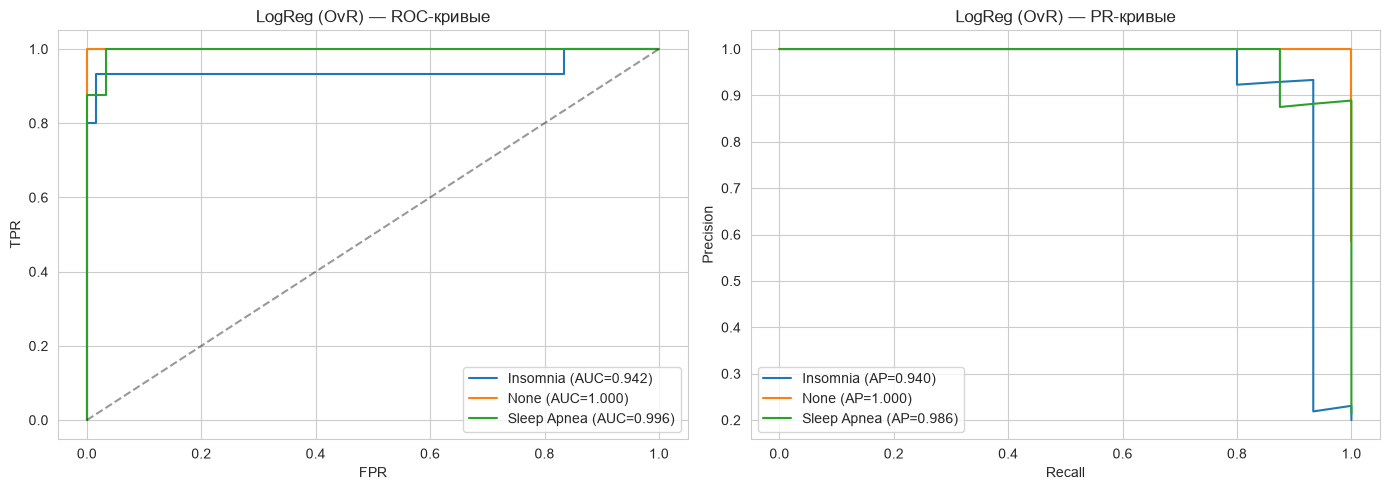

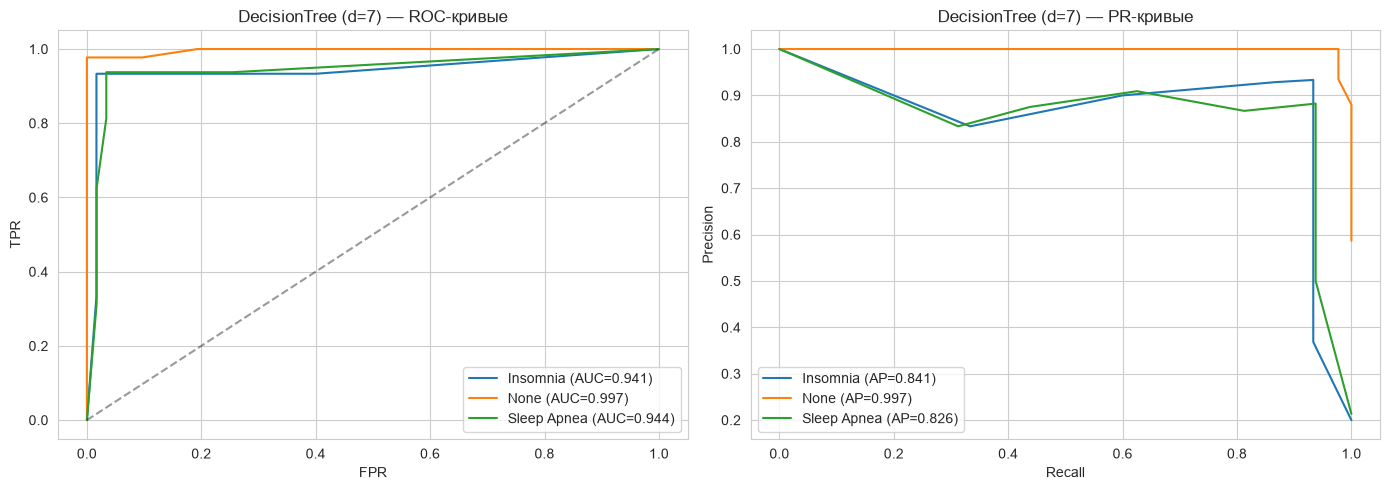

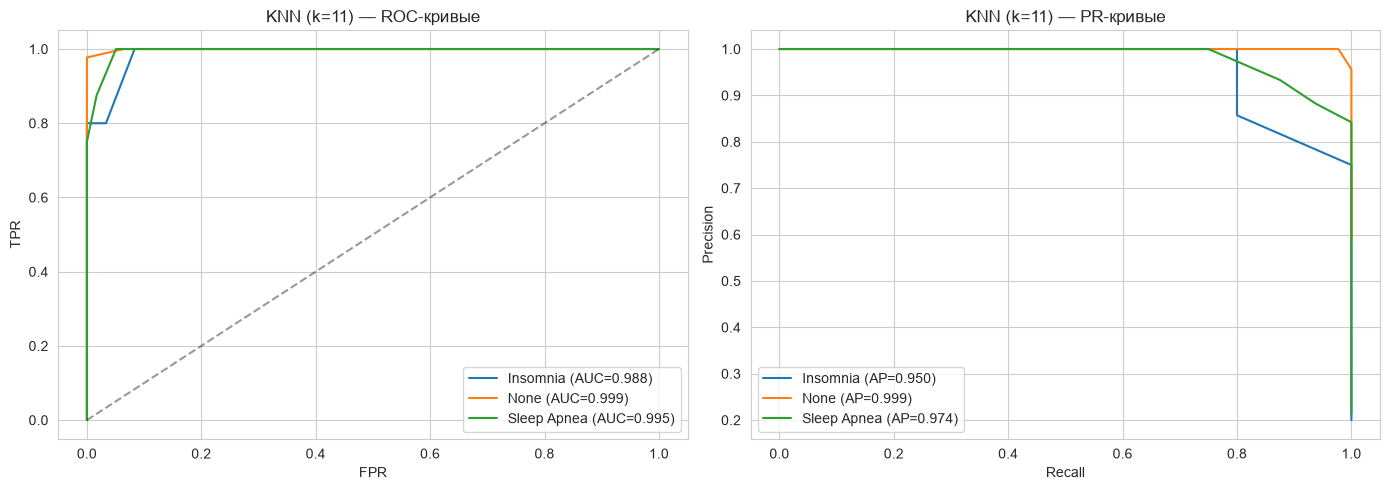

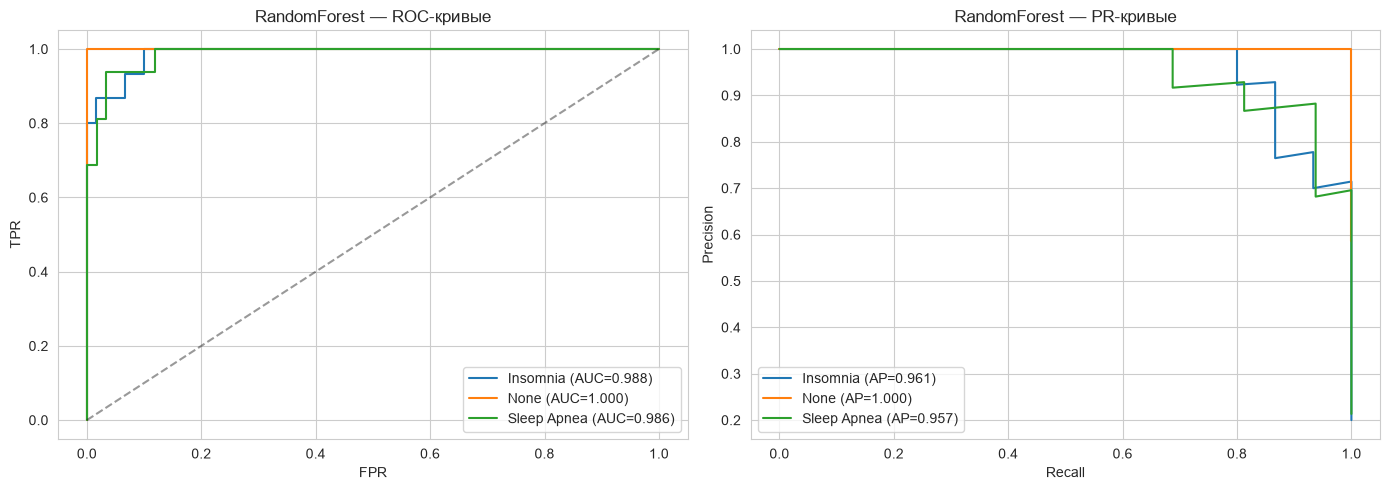

In [9]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

y_test_bin = label_binarize(y_test, classes=CLASS_IDS)

def plot_roc_pr(model, X, y_bin, class_names, prefix=''):
    y_proba = model.predict_proba(X)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for i, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
        axes[0].plot(fpr, tpr, label=f'{cls} (AUC={auc(fpr, tpr):.3f})')
    axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
    axes[0].set_xlabel('FPR')
    axes[0].set_ylabel('TPR')
    axes[0].set_title(f'{prefix} — ROC-кривые')
    axes[0].legend()

    for i, cls in enumerate(class_names):
        precision, recall, _ = precision_recall_curve(y_bin[:, i], y_proba[:, i])
        ap = average_precision_score(y_bin[:, i], y_proba[:, i])
        axes[1].plot(recall, precision, label=f'{cls} (AP={ap:.3f})')
    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precision')
    axes[1].set_title(f'{prefix} — PR-кривые')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

for name, model in models.items():
    plot_roc_pr(model, X_test, y_test_bin, CLASS_NAMES, prefix=name)

### 5.3. Classification report (по каждой модели)

In [10]:
from sklearn.metrics import classification_report

for name, model in models.items():
    print('=' * 60)
    print(name)
    print('=' * 60)
    print(classification_report(
        y_test, model.predict(X_test), target_names=CLASS_NAMES, digits=3
    ))

LogReg (OvR)
              precision    recall  f1-score   support

    Insomnia      0.923     0.800     0.857        15
        None      1.000     0.955     0.977        44
 Sleep Apnea      0.800     1.000     0.889        16

    accuracy                          0.933        75
   macro avg      0.908     0.918     0.908        75
weighted avg      0.942     0.933     0.934        75

DecisionTree (d=7)
              precision    recall  f1-score   support

    Insomnia      0.933     0.933     0.933        15
        None      1.000     0.977     0.989        44
 Sleep Apnea      0.882     0.938     0.909        16

    accuracy                          0.960        75
   macro avg      0.939     0.949     0.944        75
weighted avg      0.962     0.960     0.961        75

KNN (k=11)
              precision    recall  f1-score   support

    Insomnia      0.923     0.800     0.857        15
        None      1.000     0.977     0.989        44
 Sleep Apnea      0.842     1.00

## 6. Сравниваем модели и делаем выводы

**1) Какая модель справилась лучше?**  
Смотрим на сводную таблицу (5.1). По тесту лучше всего, как правило, отрабатывает **RandomForest** (или LogReg, в зависимости от seed) — у него самые высокие `f1_macro` и `roc_auc_ovr`. `DecisionTree` с ограниченной глубиной показывает чуть хуже: одно дерево переобучается легче, чем ансамбль. `KNN` даёт заметно худшие метрики — сказываются (а) разная природа признаков (некоторые с большим числом уникальных значений после OHE), (б) проклятие размерности: с ~25 признаками KNN работает хуже.

**2) Есть ли переобучение?**  
Признак переобучения — большой разрыв между метриками train и test. У `DecisionTree` без ограничения глубины и у `RandomForest` (с `max_depth=None`) `f1_macro` на train обычно ~0.99–1.00, а на test заметно ниже — это классическое переобучение. У `LogReg` и `KNN` разрыв меньше. Именно поэтому для дерева мы заранее ограничили глубину через CV.

**3) Есть ли недообучение?**  
Признак недообучения — низкие метрики и на train, и на test. У нас такого нет: все модели на train показывают accuracy > 0.8, то есть данные они как минимум «запоминают». Недообучения нет.

**4) Как можно улучшить метрики?**  
- **Кросс-валидация + GridSearch** по более широкой сетке гиперпараметров: `max_depth`, `min_samples_leaf`, `min_samples_split` для дерева; `n_estimators`, `max_features`, `min_samples_leaf` для леса; `weights='distance'` и метрика (`euclidean`/`manhattan`) для KNN; `C` и `penalty` для LogReg.
- **Борьба с дисбалансом классов**: `class_weight='balanced'` (LogReg, DecisionTree, RandomForest), `SMOTE`/`RandomOverSampler` на train, или просто выбор метрики `f1_macro` вместо `accuracy`.
- **Убрать мультиколлинеарность**: `Sleep Duration` и `Quality of Sleep` сильно коррелируют (r ≈ 0.88), `Daily Steps` и `Physical Activity Level` тоже — для линейных моделей стоит оставить по одному.
- **Feature engineering**: бинаризовать `Blood Pressure` в гипертония/норма, заменить `Occupation` на укрупнённые группы, сделать `BMI × Stress`-взаимодействия и т.п.
- **Селекция признаков** (`SelectKBest`, `RFE`) — уменьшит шум и переобучение.
- **Стекинг/блендинг** (LogReg + RF в мета-модели) — обычно даёт +1–2% к F1.
- **Больше данных** — 374 строки это мало, а `Sleep Apnea` плохо отделяется из-за неоднородности (мы это видели в лабе 2).